# Исследовательский ноутбук прогнозирование депозитов населения Беларуси
Помогают ли данные о новых депозитных договорах точнее прогнозировать остатки на счетах населения? Проверим это на статистике НБРБ: сравним простые прогнозы с Ridge, затем добавим показатели новых договоров и регуляторных условий. Рублёвые и валютные депозиты рассмотрим отдельно.
Есть важная оговорка: новый договор — не обязательно новые деньги. В статистику входят и продления вкладов.
Используем остатки за декабрь 2014 — август 2026 года, новые договоры — с января 2020 года. Этот период уже изучался при разработке моделей; здесь мы воспроизводим расчёты. Независимая проверка потребует новых данных.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
file_path = Path("data/broadmoney_ru.xlsx")
print("Файл найден:", file_path.exists())
excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names

Файл найден: True


['2015',
 '2016',
 '2017',
 '2018',
 '2019',
 '2020',
 '2021',
 '2022',
 '2023',
 '2024',
 '2025',
 '2026']

In [3]:
def read_stock_year(excel_file, year):
    raw = pd.read_excel(excel_file, sheet_name=str(year), header=None)

    stocks = raw.iloc[[6, 10, 17, 20, 29, 32], 1:].T.copy()
    stocks.columns = [
        "byn_transfer",
        "byn_other",
        "fx_transfer_byn",
        "fx_other_byn",
        "fx_transfer_usd",
        "fx_other_usd",
    ]
    stocks = stocks.apply(pd.to_numeric, errors="raise")

    dates = pd.to_datetime(raw.iloc[3, 1:].values)
    stocks.index = dates.to_period("M") - 1
    stocks.index.name = "month"

    stocks["byn_stock_mln"] = (
        stocks["byn_transfer"] + stocks["byn_other"]
    )
    stocks["fx_stock_usd_mln"] = (
        stocks["fx_transfer_usd"] + stocks["fx_other_usd"]
    )
    stocks["fx_stock_byn_mln"] = (
        stocks["fx_transfer_byn"] + stocks["fx_other_byn"]
    )

    stocks["e_stock"] = (
        stocks["fx_stock_byn_mln"] / stocks["fx_stock_usd_mln"]
    )

    return stocks

In [4]:
stocks_2016 = read_stock_year(excel_file, 2016)
stocks_2016.head()

,byn_transfer,byn_other,fx_transfer_byn,fx_other_byn,fx_transfer_usd,fx_other_usd,byn_stock_mln,fx_stock_usd_mln,fx_stock_byn_mln,e_stock
month,,,,,,,,,,
2015-12,1405.9848,2614.4611,968.0290,14282.2698,521.315,7691.459,4020.4459,8212.774,15250.2988,1.8569
2016-01,1288.0616,2465.5978,889.7284,16277.2848,419.011,7665.671,3753.6594,8084.682,17167.0132,2.1234
2016-02,1235.0413,2428.7039,841.3812,16216.9725,391.668,7549.098,3663.7452,7940.766,17058.3537,2.1482
2016-03,1179.5471,2471.2406,757.4216,15177.4053,376.209,7538.571,3650.7877,7914.780,15934.8269,2.0133
2016-04,1349.7180,2494.9795,753.2308,14431.5682,388.624,7445.861,3844.6975,7834.485,15184.7990,1.9382


In [5]:
year_tables = []

for year in range(2015, 2027):
    year_stocks = read_stock_year(excel_file, year)
    year_tables.append(year_stocks)

stocks = pd.concat(year_tables).sort_index()

In [6]:
print("Размер:", stocks.shape)
print("Первый месяц:", stocks.index.min())
print("Последний месяц:", stocks.index.max())
print("Повторяющихся месяцев:", stocks.index.duplicated().sum())
print("Пропуски:")
print(stocks.isna().sum())

display(stocks.tail())

Размер: (141, 10)
Первый месяц: 2014-12
Последний месяц: 2026-08
Повторяющихся месяцев: 0
Пропуски:
byn_transfer        0
byn_other           0
fx_transfer_byn     0
fx_other_byn        0
fx_transfer_usd     0
fx_other_usd        0
byn_stock_mln       0
fx_stock_usd_mln    0
fx_stock_byn_mln    0
e_stock             0
dtype: int64


,byn_transfer,byn_other,fx_transfer_byn,fx_other_byn,fx_transfer_usd,fx_other_usd,byn_stock_mln,fx_stock_usd_mln,fx_stock_byn_mln,e_stock
month,,,,,,,,,,
2026-04,10932.757000,17023.781000,7547.694000,6772.343000,2673.642933,2398.987956,27956.538000,5072.630889,14320.037000,2.8230
2026-05,11434.217000,17459.395000,7382.222000,6655.343000,2675.105812,2411.705682,28893.612000,5086.811494,14037.565000,2.7596
2026-06,11768.758305,17862.671467,7722.407700,6861.992491,2656.852577,2360.831381,29631.429772,5017.683958,14584.400191,2.9066
2026-07,12224.331068,18375.561653,7619.587075,6862.753145,2615.448830,2355.663044,30599.892721,4971.111873,14482.340220,2.9133
2026-08,11885.148445,18939.671896,7902.094118,7034.527505,2599.715133,2314.293823,30824.820341,4914.008956,14936.621623,3.0396


In [7]:
expected_months = pd.period_range(
    start="2014-12",
    end="2026-08",
    freq="M",
)

missing_months = expected_months.difference(stocks.index)
extra_months = stocks.index.difference(expected_months)

print("Отсутствующие месяцы:", missing_months)
print("Лишние месяцы:", extra_months)

assert stocks.index.is_unique
assert stocks.index.equals(expected_months)
assert stocks.notna().all().all()


Отсутствующие месяцы: PeriodIndex([], dtype='period[M]')
Лишние месяцы: PeriodIndex([], dtype='period[M]')


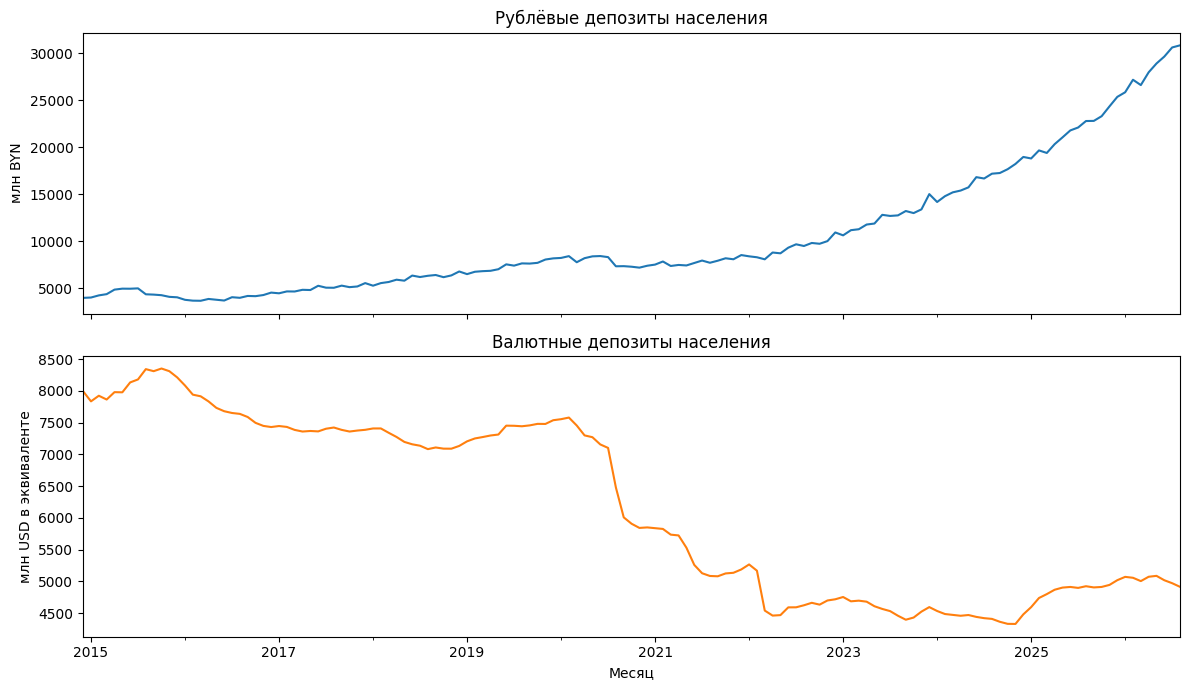

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

stocks["byn_stock_mln"].plot(ax=axes[0], color="tab:blue")
axes[0].set_title("Рублёвые депозиты населения")
axes[0].set_ylabel("млн BYN")

stocks["fx_stock_usd_mln"].plot(ax=axes[1], color="tab:orange")
axes[1].set_title("Валютные депозиты населения")
axes[1].set_ylabel("млн USD в эквиваленте")
axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

         byn_stock_mln  fx_stock_usd_mln
month                                   
2014-12            NaN               NaN
2015-01       34.93555          -158.122
2015-02      227.62483            88.506
2015-03      132.27856           -59.733
2015-04      480.82123           116.278


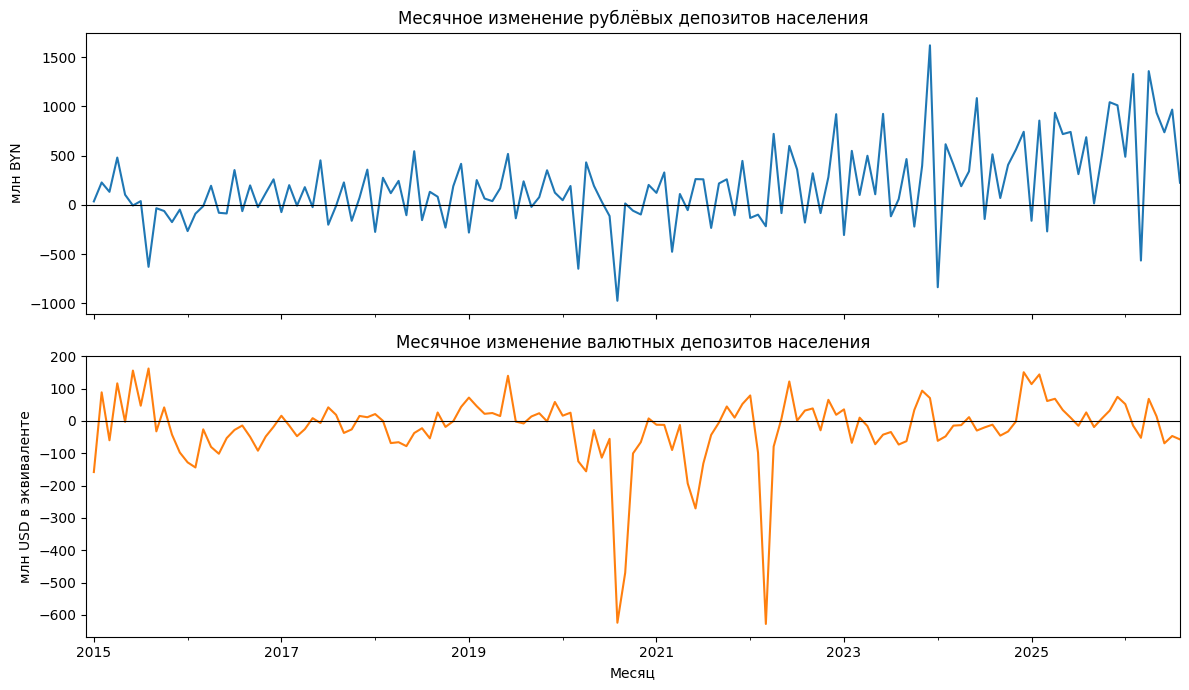

In [9]:
stock_changes = stocks[["byn_stock_mln", "fx_stock_usd_mln"]].diff()

print(stock_changes.head())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

stock_changes["byn_stock_mln"].plot(ax=axes[0], color="tab:blue")
axes[0].set_title("Месячное изменение рублёвых депозитов населения")
axes[0].set_ylabel("млн BYN")
axes[0].axhline(0, color="black", linewidth=0.8)

stock_changes["fx_stock_usd_mln"].plot(ax=axes[1], color="tab:orange")
axes[1].set_title("Месячное изменение валютных депозитов населения")
axes[1].set_ylabel("млн USD в эквиваленте")
axes[1].set_xlabel("Месяц")
axes[1].axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()


In [10]:
stock_levels = stocks[["byn_stock_mln", "fx_stock_usd_mln"]].copy()

naive_predictions = stock_levels.shift(2)

comparison = pd.DataFrame({
    "actual_byn": stock_levels["byn_stock_mln"],
    "naive_byn": naive_predictions["byn_stock_mln"],
    "actual_fx": stock_levels["fx_stock_usd_mln"],
    "naive_fx": naive_predictions["fx_stock_usd_mln"],
})

comparison.tail(6)

,actual_byn,naive_byn,actual_fx,naive_fx
month,,,,
2026-03,26597.101000,25832.827000,5004.281551,5070.900126
2026-04,27956.538000,27163.394000,5072.630889,5056.487046
2026-05,28893.612000,26597.101000,5086.811494,5004.281551
2026-06,29631.429772,27956.538000,5017.683958,5072.630889
2026-07,30599.892721,28893.612000,4971.111873,5086.811494
2026-08,30824.820341,29631.429772,4914.008956,5017.683958


## Наивный подход

На дату выпуска прогноза в конце месяца t считаем известным остаток за t−1. Прогнозируем остаток за t+1: наивный прогноз сохраняет последнее известное значение. Поэтому относительно месяца цели используем сдвиг на два месяца. Оценочный период — сентябрь 2025 — август 2026. Это проверка на текущей версии статистики при принятом допущении о доступности данных.

In [11]:
evaluation = comparison.loc["2025-09":"2026-08"].copy()
evaluation["err_byn"] = evaluation["actual_byn"] - evaluation["naive_byn"]
evaluation["err_fx"] = evaluation["actual_fx"] - evaluation["naive_fx"]

naive_mae_byn = evaluation["err_byn"].abs().mean()
naive_mae_fx = evaluation["err_fx"].abs().mean()

print(f"MAE BYN: {naive_mae_byn:.3f} млн BYN")
print(f"MAE FX: {naive_mae_fx:.3f} млн USD в эквиваленте")


MAE BYN: 1380.581 млн BYN
MAE FX: 64.077 млн USD в эквиваленте


## Продолжение тренда Drift12

Используем геометрический вариант: повторяем средний месячный логарифмический прирост за последние 12 месяцев. От последнего известного остатка продолжаем его на два месяца. Для месяца цели m формула: V̂_m = V_{m−2} × (V_{m−2} / V_{m−14}) ** (2/12). Отдельно прогнозируем компоненты, затем складываем их. Линейный Drift12 был бы другим ориентиром; здесь во всех сравнениях применяется одна геометрическая формула.

In [12]:
components = stocks[[
    "byn_transfer",
    "byn_other",
    "fx_transfer_usd",
    "fx_other_usd",
]]

last_available = components.shift(2)
year_earlier = components.shift(14)

growth_factor = (last_available / year_earlier) ** (2 / 12)

component_predictions = last_available * growth_factor

drift_predictions = pd.DataFrame({
    "byn_stock_mln": (
        component_predictions["byn_transfer"]
        + component_predictions["byn_other"]
    ),
    "fx_stock_usd_mln": (
        component_predictions["fx_transfer_usd"]
        + component_predictions["fx_other_usd"]
    ),
})

In [13]:
actual = stock_levels.loc["2025-09":"2026-08"]
predicted = drift_predictions.loc["2025-09":"2026-08"]

drift_mae = (actual - predicted).abs().mean()

baseline_metrics = pd.DataFrame({
    "Naive": [naive_mae_byn, naive_mae_fx],
    "Drift12": [
        drift_mae["byn_stock_mln"],
        drift_mae["fx_stock_usd_mln"],
    ],
}, index=["BYN, млн BYN", "FX, млн USD в эквиваленте"])

display(baseline_metrics.round(3))

,Naive,Drift12
"BYN, млн BYN",1380.581,505.443
"FX, млн USD в эквиваленте",64.077,82.009


## Подготовка признаков и цели для Ridge

Сначала разбираем один компонент — переводные депозиты в BYN. Цель — 100 × log(V_{t+1}/V_{t−1}). Стандартизация оценивается внутри каждой обучающей выборки.

In [14]:
import numpy as np

log_components = np.log(components)

targets = 100 * (log_components.shift(-1) - log_components.shift(1))

targets.head()

,byn_transfer,byn_other,fx_transfer_usd,fx_other_usd
month,,,,
2014-12,NaN,NaN,NaN,NaN
2015-01,3.212640,7.841276,-7.590024,-0.467855
2015-02,-1.279194,12.340851,-0.711297,0.429399
2015-03,5.820283,16.732220,1.010554,0.693550
2015-04,23.923555,8.273982,4.875115,1.229626


In [15]:
monthly_log_growth = log_components.diff()

growth_lag_1 = monthly_log_growth.shift(1)
growth_lag_2 = monthly_log_growth.shift(2)
growth_lag_3 = monthly_log_growth.shift(3)

average_growth_12 = log_components.diff(12).shift(1) / 12

In [16]:
component = "byn_transfer"

design = pd.DataFrame({
    "base": components[component].shift(1),
    "g0": growth_lag_1[component],
    "g1": growth_lag_2[component],
    "g2": growth_lag_3[component],
    "g12": average_growth_12[component],
    "y": targets[component],
})

design.loc["2020-02":].head()

,base,g0,g1,g2,g12,y
month,,,,,,
2020-02,2943.646,-0.029067,0.004889,0.074605,0.017595,-10.601238
2020-03,3105.459,0.053513,-0.029067,0.004889,0.015745,1.706677
2020-04,2647.555,-0.159525,0.053513,-0.029067,0.002181,23.177420
2020-05,3158.914,0.176592,-0.159525,0.053513,0.017627,6.652548
2020-06,3338.130,0.055182,0.176592,-0.159525,0.018846,0.969691


In [17]:
fx_change = np.log(stocks["e_stock"]).diff().shift(1)

design["fx"] = fx_change

design.loc["2020-02":].head()

,base,g0,g1,g2,g12,y,fx
month,,,,,,,
2020-02,2943.646,-0.029067,0.004889,0.074605,0.017595,-10.601238,0.016080
2020-03,3105.459,0.053513,-0.029067,0.004889,0.015745,1.706677,0.044063
2020-04,2647.555,-0.159525,0.053513,-0.029067,0.002181,23.177420,0.152602
2020-05,3158.914,0.176592,-0.159525,0.053513,0.017627,6.652548,-0.065997
2020-06,3338.130,0.055182,0.176592,-0.159525,0.018846,0.969691,-0.009237


In [18]:
macro = pd.read_csv("data/input_panel.csv")
macro.index = pd.PeriodIndex(macro["month"], freq="M")

design["spread_l1"] = macro["spread_l1"]
design["real_rate_proxy_l1"] = macro["real_rate_proxy_l1"]

design.loc["2020-02":].head()

,base,g0,g1,g2,g12,y,fx,spread_l1,real_rate_proxy_l1
month,,,,,,,,,
2020-02,2943.646,-0.029067,0.004889,0.074605,0.017595,-10.601238,0.016080,8.82,4.921025
2020-03,3105.459,0.053513,-0.029067,0.004889,0.015745,1.706677,0.044063,8.71,5.062328
2020-04,2647.555,-0.159525,0.053513,-0.029067,0.002181,23.177420,0.152602,8.59,4.343703
2020-05,3158.914,0.176592,-0.159525,0.053513,0.017627,6.652548,-0.065997,9.60,4.937760
2020-06,3338.130,0.055182,0.176592,-0.159525,0.018846,0.969691,-0.009237,10.55,6.562074


In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

features = [
    "g0", "g1", "g2", "g12", "fx",
    "spread_l1", "real_rate_proxy_l1",
]

design = design.loc["2020-02":].dropna(subset=features + ["y"]).copy()

origin = pd.Period("2025-08", freq="M")

train = design.loc[
    (design.index + 1 <= origin - 1) 
].dropna(subset=features + ["y"]).copy()

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1),
)

model.fit(train[features], train["y"])

X_predict = design.loc[[origin], features]

predicted_growth = model.predict(X_predict)[0]

growth_factor = np.exp(predicted_growth/100)

base = design.loc[origin, "base"]

predicted_stock = base * growth_factor

print(f"Прогноз изменения: {(growth_factor - 1) * 100:.2f}%")
print(f"Прогноз остатка: {predicted_stock:.3f}")

Прогноз изменения: 2.16%
Прогноз остатка: 9209.535


In [20]:
actual_stock = stocks.loc[origin + 1, component]

error = actual_stock - predicted_stock
absolute_error = abs(error)

print(f"Месяц цели: {origin + 1}")
print(f"Прогноз: {predicted_stock:.3f}")
print(f"Факт: {actual_stock:.3f}")
print(f"Абсолютная ошибка: {absolute_error:.3f}")

Месяц цели: 2025-09
Прогноз: 9209.535
Факт: 8969.282
Абсолютная ошибка: 240.253


## Последовательная проверка одного компонента

Для каждой даты модель обучается заново. Обучающие цели заканчиваются не позднее t−1. Оценочные цели — следующие 12 месяцев.

In [21]:
origins = pd.period_range("2025-08", "2026-07", freq="M")
results = []

for origin in origins:
    train = design.loc[
        (design.index + 1 <= origin - 1) 
    ].dropna(subset=features + ["y"]).copy()

    assert len(train) >= 48, "Недостаточно обучающих наблюдений"

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=1),
    )
    model.fit(train[features], train["y"])

    X_predict = design.loc[[origin], features]
    predicted_growth = model.predict(X_predict)[0]

    base = design.loc[origin, "base"]
    predicted_stock = base * np.exp(predicted_growth / 100)

    actual_stock = stocks.loc[origin + 1, component]

    results.append({
        "month": origin + 1,
        "actual": actual_stock,
        "prediction": predicted_stock,
    })

ridge_results = pd.DataFrame(results).set_index("month")

ridge_results["absolute_error"] = (
    ridge_results["actual"] - ridge_results["prediction"]
).abs()

ridge_mae = ridge_results["absolute_error"].mean()

display(ridge_results)
print(f"MAE Ridge: {ridge_mae:.3f}")

,actual,prediction,absolute_error
month,,,
2025-09,8969.282000,9209.534535,240.252535
2025-10,9045.612000,9637.818721,592.206721
2025-11,9652.609000,9530.699790,121.909210
2025-12,10187.556000,9539.668125,647.887875
2026-01,10171.843000,10061.589175,110.253825
2026-02,10981.970000,10284.482742,697.487258
2026-03,9981.898000,10503.245264,521.347264
2026-04,10932.757000,11035.871176,103.114176
2026-05,11434.217000,10731.507016,702.709984


MAE Ridge: 397.984


In [22]:
# Используем полный исходный ряд выбранного компонента.
component_levels = stocks[component].copy()

comparison_component = ridge_results[["actual", "prediction"]].rename(
    columns={"prediction": "Ridge"}
)

comparison_component["Naive"] = component_levels.shift(2).reindex(
    comparison_component.index
)

component_drift = component_levels.shift(2) * (
    component_levels.shift(2) / component_levels.shift(14)
) ** (2 / 12)

comparison_component["Drift12"] = component_drift.reindex(
    comparison_component.index
)

assert comparison_component.notna().all().all(), "Остались пропуски"
display(comparison_component.round(3))

errors = comparison_component[["Naive", "Drift12", "Ridge"]].sub(
    comparison_component["actual"], axis=0
).abs()

mae_component = errors.mean().rename("MAE").to_frame()
mae_component["Улучшение к Naive, %"] = (
    1 - mae_component["MAE"] / mae_component.loc["Naive", "MAE"]
) * 100

display(mae_component.round(3))

,actual,Ridge,Naive,Drift12
month,,,,
2025-09,8969.282,9209.535,9014.377,9348.839
2025-10,9045.612,9637.819,9359.521,9718.795
2025-11,9652.609,9530.700,8969.282,9296.529
2025-12,10187.556,9539.668,9045.612,9377.577
2026-01,10171.843,10061.589,9652.609,10047.507
2026-02,10981.970,10284.483,10187.556,10587.055
2026-03,9981.898,10503.245,10171.843,10680.518
2026-04,10932.757,11035.871,10981.970,11554.334
2026-05,11434.217,10731.507,9981.898,10460.922


,MAE,"Улучшение к Naive, %"
Naive,577.659,0.000
Drift12,497.921,13.804
Ridge,397.984,31.104


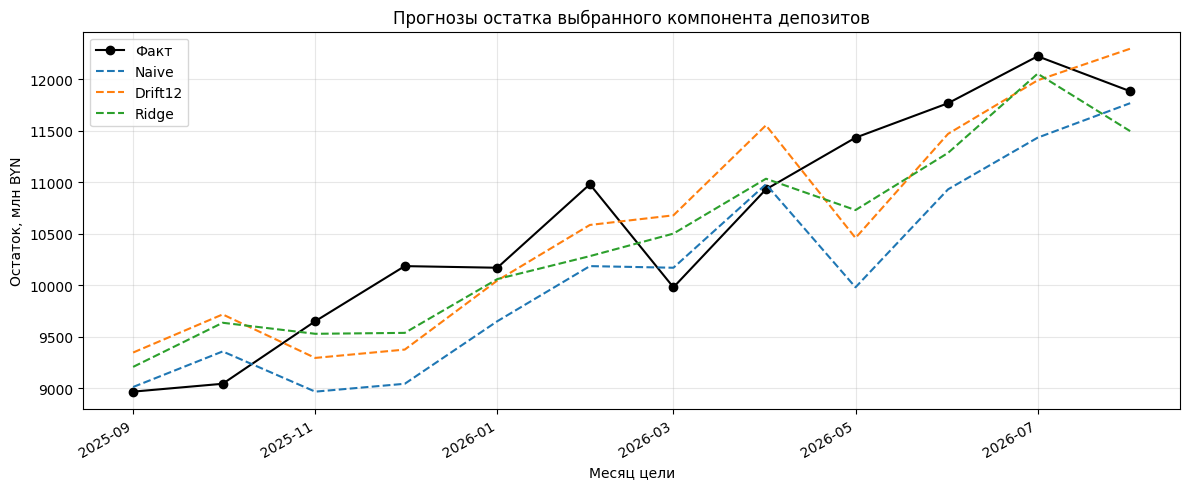

In [23]:
plot_data = comparison_component.copy()
plot_data.index = plot_data.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    plot_data.index, plot_data["actual"],
    label="Факт", color="black", marker="o",
)

for name in ["Naive", "Drift12", "Ridge"]:
    ax.plot(
        plot_data.index, plot_data[name],
        label=name, linestyle="--",
    )

ax.set_title("Прогнозы остатка выбранного компонента депозитов")
ax.set_xlabel("Месяц цели")
ax.set_ylabel("Остаток, млн BYN")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Подготовка данных для четырёх компонентов

Функция повторяет предыдущие вычисления для выбранного столбца. Входные макропризнаки уже лагированы.

In [24]:
def make_design(stocks, macro, component):
    level = stocks[component]
    log_level = np.log(level)
    growth = log_level.diff()

    design = pd.DataFrame(index=stocks.index)

    design["base"] = level.shift(1)

    design["g0"] = growth.shift(1)
    design["g1"] = growth.shift(2)
    design["g2"] = growth.shift(3)
    design["g12"] = log_level.diff(12).shift(1) / 12

    design["fx"] = np.log(stocks["e_stock"]).diff().shift(1)

    design["spread_l1"] = macro["spread_l1"]
    design["real_rate_proxy_l1"] = macro["real_rate_proxy_l1"]

    design["y"] = 100 * (
        log_level.shift(-1) - log_level.shift(1)
    )

    return design.loc["2020-02":].copy()

In [25]:
component_columns = [
    "byn_transfer",
    "byn_other",
    "fx_transfer_usd",
    "fx_other_usd",
]

origins = pd.period_range("2025-08", "2026-07", freq="M")

component_results = {}

for component_name in component_columns:
    design_component = make_design(stocks, macro, component_name)
    results = []

    for origin in origins:
        train = design_component.loc[
            design_component.index + 1 <= origin - 1
        ].dropna(subset=features + ["y"])

        assert len(train) >= 48, "Недостаточно обучающих наблюдений"

        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=1),
        )

        model.fit(train[features], train["y"])

        X_predict = design_component.loc[[origin], features]
        predicted_growth = model.predict(X_predict)[0]

        base = design_component.loc[origin, "base"]
        predicted_stock = base * np.exp(predicted_growth / 100)

        results.append({
            "month": origin + 1,
            "actual": stocks.loc[origin + 1, component_name],
            "prediction": predicted_stock,
        })

    component_results[component_name] = (
        pd.DataFrame(results).set_index("month")
    )

## Общие остатки BYN и FX

Складываем прогнозы компонентов внутри каждой валютной группы. Ошибку считаем после сложения: ошибки компонентов могут компенсироваться.

In [26]:
ridge_totals = pd.DataFrame(index=origins + 1)
ridge_totals.index.name = "month"

ridge_totals["actual_byn"] = stocks["byn_stock_mln"].reindex(
    ridge_totals.index
)

ridge_totals["ridge_byn"] = (
    component_results["byn_transfer"]["prediction"]
    + component_results["byn_other"]["prediction"]
)

ridge_totals["actual_fx"] = stocks["fx_stock_usd_mln"].reindex(
    ridge_totals.index
)

ridge_totals["ridge_fx"] = (
    component_results["fx_transfer_usd"]["prediction"]
    + component_results["fx_other_usd"]["prediction"]
)

assert ridge_totals.notna().all().all(), "Есть пропуски"

display(ridge_totals.round(3))

ridge_mae_byn = (ridge_totals["actual_byn"] - ridge_totals["ridge_byn"]).abs().mean()
ridge_mae_fx = (ridge_totals["actual_fx"] - ridge_totals["ridge_fx"]).abs().mean()

print(f"MAE BYN: {ridge_mae_byn:.3f} млн BYN")
print(f"MAE FX: {ridge_mae_fx:.3f} млн USD-эквивалента")

,actual_byn,ridge_byn,actual_fx,ridge_fx
month,,,,
2025-09,22787.356,22810.374,4904.724,4853.628
2025-10,23288.100,23571.678,4912.231,4929.796
2025-11,24331.794,23971.290,4944.254,4850.556
2025-12,25343.870,24427.659,5018.849,4897.636
2026-01,25832.827,25439.330,5070.900,4949.603
2026-02,27163.394,26256.716,5056.487,5057.744
2026-03,26597.101,27045.424,5004.282,5131.094
2026-04,27956.538,28139.444,5072.631,5063.099
2026-05,28893.612,28144.382,5086.811,4971.742


MAE BYN: 482.334 млн BYN
MAE FX: 89.386 млн USD-эквивалента


## Сравнение общих прогнозов с ориентирами

Следующий шаг - оценка Naive, геометрического Drift12 и Ridge на одинаковых 12 месяцах. BYN измеряется в млн BYN, FX - в млн USD-эквивалента. Величины ошибок двух валютных групп напрямую не сопоставляются. Положительное улучшение означает снижение MAE относительно ориентира. Результат на этом уже изученном периоде не доказывает устойчивого превосходства модели.

In [27]:
total_comparison = ridge_totals.copy()

for suffix, column in [("byn", "byn_stock_mln"), ("fx", "fx_stock_usd_mln")]:
    total_comparison[f"naive_{suffix}"] = naive_predictions[column].reindex(
        total_comparison.index
    )
    total_comparison[f"drift_{suffix}"] = drift_predictions[column].reindex(
        total_comparison.index
    )

assert total_comparison.notna().all().all(), "В сравнении есть пропуски"
assert len(total_comparison) == 12

summary_rows = []
for suffix, label in [("byn", "BYN, млн BYN"), ("fx", "FX, млн USD-эквивалента")]:
    actual_values = total_comparison[f"actual_{suffix}"]
    row = {"Показатель": label}
    for name, prefix in [("Naive", "naive"), ("Drift12", "drift"), ("Ridge", "ridge")]:
        row[name] = (
            actual_values - total_comparison[f"{prefix}_{suffix}"]
        ).abs().mean()
    row["Ridge к Naive, %"] = 100 * (1 - row["Ridge"] / row["Naive"])
    row["Ridge к Drift12, %"] = 100 * (1 - row["Ridge"] / row["Drift12"])
    summary_rows.append(row)

total_metrics = pd.DataFrame(summary_rows).set_index("Показатель")
with pd.option_context("display.max_columns", None):
    display(total_metrics.round(3))

,Naive,Drift12,Ridge,"Ridge к Naive, %","Ridge к Drift12, %"
Показатель,,,,,
"BYN, млн BYN",1380.581,505.443,482.334,65.063,4.572
"FX, млн USD-эквивалента",64.077,82.009,89.386,-39.499,-8.996


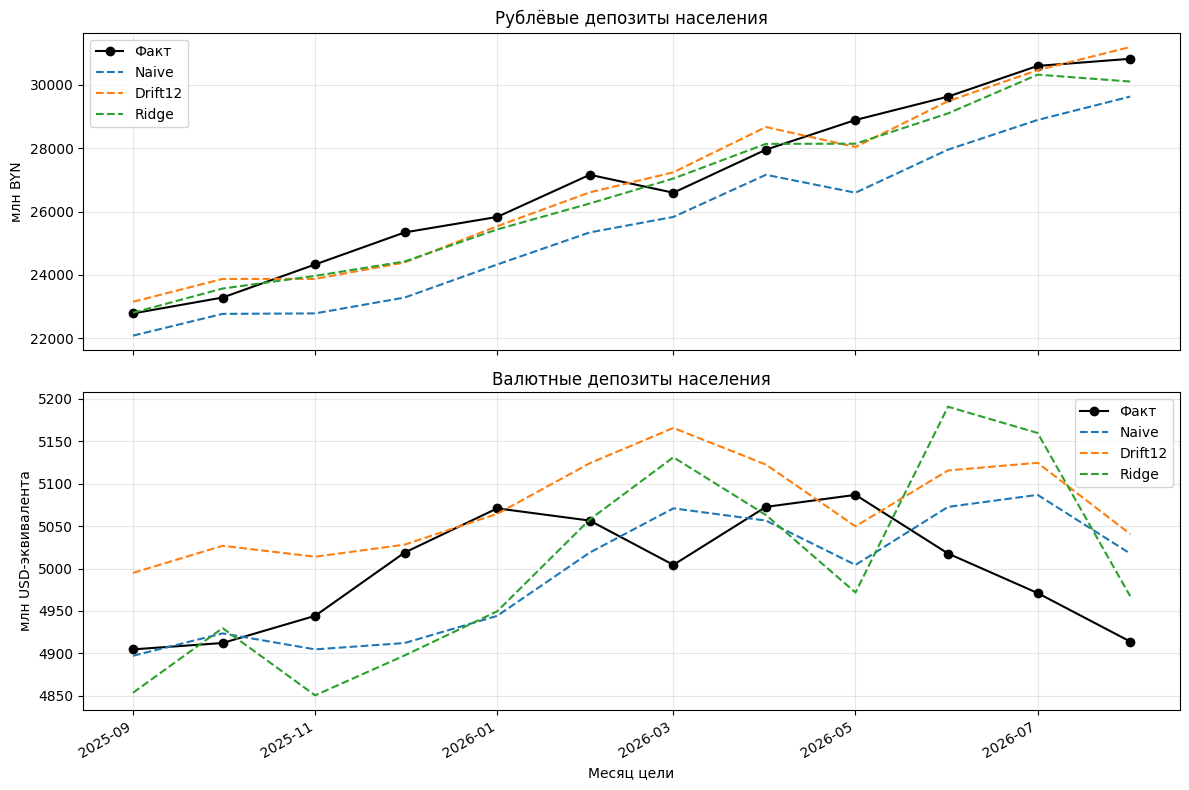

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
plot_dates = total_comparison.index.to_timestamp()

for ax, suffix, title, unit in [
    (axes[0], "byn", "Рублёвые депозиты населения", "млн BYN"),
    (axes[1], "fx", "Валютные депозиты населения", "млн USD-эквивалента"),
]:
    ax.plot(plot_dates, total_comparison[f"actual_{suffix}"],
            color="black", marker="o", label="Факт")
    for prefix, name in [("naive", "Naive"), ("drift", "Drift12"), ("ridge", "Ridge")]:
        ax.plot(plot_dates, total_comparison[f"{prefix}_{suffix}"],
                linestyle="--", label=name)
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.grid(alpha=0.3)
    ax.legend()

axes[1].set_xlabel("Месяц цели")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Что показало сравнение

На интервале сентябрь 2025 — август 2026 базовый Ridge по компонентам показал MAE **482,334 млн BYN** против **505,443** у Drift12 и **1380,581** у Naive. Наблюдаемое снижение ошибки к Drift12 составляет **4,57%**.

Для валютных остатков Ridge получил MAE **89,386 млн USD-эквивалента**, Drift12 — **82,009**, Naive — **64,077**. На этом периоде простое сохранение последнего известного уровня оказалось точнее обеих других моделей.

Снижение BYN-ошибки на 12 месяцах само по себе не доказывает статистически устойчивый выигрыш. Здесь проверен базовый набор признаков: история остатков, изменение коэффициента валютного пересчёта и два макропризнака. Признаки новых договоров и policy в этот Ridge ещё не добавлены.

Следующий исследовательский шаг — добавить показатель новых договоров и сравнить версии с ним и без него на одинаковых датах и обучающих строках.

In [29]:
features_flow = features + ["flow"]

designs_flow = {}

for component_name in component_columns:
    table = make_design(stocks, macro, component_name)

    table["flow"] = macro["flow_feature"]

    designs_flow[component_name] = table

display(
    designs_flow["byn_transfer"][features_flow + ["y"]].head()
)

,g0,g1,g2,g12,fx,spread_l1,real_rate_proxy_l1,flow,y
month,,,,,,,,,
2020-02,-0.029067,0.004889,0.074605,0.017595,0.016080,8.82,4.921025,0.559281,-10.601238
2020-03,0.053513,-0.029067,0.004889,0.015745,0.044063,8.71,5.062328,0.592700,1.706677
2020-04,-0.159525,0.053513,-0.029067,0.002181,0.152602,8.59,4.343703,0.651509,23.177420
2020-05,0.176592,-0.159525,0.053513,0.017627,-0.065997,9.60,4.937760,0.556762,6.652548
2020-06,0.055182,0.176592,-0.159525,0.018846,-0.009237,10.55,6.562074,0.569877,0.969691


In [30]:
table

,base,g0,g1,g2,g12,fx,spread_l1,real_rate_proxy_l1,y,flow
month,,,,,,,,,,
2020-02,6198.796000,-0.002826,0.003545,-0.002537,0.000710,0.016080,8.82,4.921025,-2.726617,0.559281
2020-03,6172.424000,-0.004263,-0.002826,0.003545,0.000280,0.044063,8.71,5.062328,-5.560864,0.592700
2020-04,6032.062000,-0.023003,-0.004263,-0.002826,-0.001674,0.152602,8.59,4.343703,-4.479333,0.651509
2020-05,5838.553000,-0.032606,-0.023003,-0.004263,-0.004296,-0.065997,9.60,4.937760,-3.538132,0.556762
2020-06,5767.828000,-0.012187,-0.032606,-0.023003,-0.005460,-0.009237,10.55,6.562074,-3.618619,0.569877
...,...,...,...,...,...,...,...,...,...,...
2026-04,2368.051037,-0.026094,-0.013077,-0.000919,-0.008486,0.033951,7.00,5.886012,1.826698,0.175675
2026-05,2398.987956,0.012980,-0.026094,-0.013077,-0.007081,-0.044276,7.08,5.821095,-1.603313,0.187734
2026-06,2411.705682,0.005287,0.012980,-0.026094,-0.006246,-0.022714,6.79,6.338976,-2.351201,0.166125


In [31]:
component_results_flow = {}
for component_name in component_columns:
    table = designs_flow[component_name]
    results_flow = []

    for origin in origins:
        available = table.loc[
            table.index + 1 <= origin - 1
        ]

        train_base = available.dropna(subset=features + ["y"])
        train_flow = available.dropna(subset=features_flow + ["y"])

        model_flow = make_pipeline(
            StandardScaler(),
            Ridge(alpha=1)
        )

        model_flow.fit(
            train_flow[features_flow],
            train_flow["y"]
        )

        X_predict = table.loc[[origin], features_flow]

        predicted_growth = model_flow.predict(X_predict)[0]

        base = table.loc[origin, "base"]

        predicted_stock = base * np.exp(predicted_growth / 100)

        results_flow.append({
            "month": origin + 1,
            "actual": stocks.loc[origin + 1, component_name],
            "prediction": predicted_stock,
        })

    component_results_flow[component_name] = (
    pd.DataFrame(results_flow).set_index("month")
)

display(component_results_flow["byn_transfer"].round(3))

,actual,prediction
month,,
2025-09,8969.282,9377.148
2025-10,9045.612,9807.212
2025-11,9652.609,9711.289
2025-12,10187.556,9675.721
2026-01,10171.843,10179.717
2026-02,10981.970,10386.581
2026-03,9981.898,10615.559
2026-04,10932.757,11183.813
2026-05,11434.217,10894.875


In [32]:
flow_comparison = ridge_totals.copy()

flow_comparison["ridge_flow_byn"] = (
    component_results_flow["byn_transfer"]["prediction"]
    + component_results_flow["byn_other"]["prediction"]
)

flow_comparison["ridge_flow_fx"] = (
    component_results_flow["fx_transfer_usd"]["prediction"]
    + component_results_flow["fx_other_usd"]["prediction"]
)

assert flow_comparison.notna().all().all(), "Есть пропуски"

flow_metrics_rows = []

for suffix, label in [
    ("byn", "BYN, млн BYN"),
    ("fx", "FX, млн USD-эквивалента"),
]:
    actual = flow_comparison[f"actual_{suffix}"]

    mae_base = (
        actual - flow_comparison[f"ridge_{suffix}"]
    ).abs().mean()

    mae_flow = (
        actual - flow_comparison[f"ridge_flow_{suffix}"]
    ).abs().mean()

    flow_metrics_rows.append({
        "Показатель": label,
        "Ridge": mae_base,
        "Ridge + flow": mae_flow,
        "Снижение MAE": mae_base - mae_flow,
        "Улучшение, %": 100 * (1 - mae_flow / mae_base),
    })

flow_metrics = pd.DataFrame(flow_metrics_rows).set_index("Показатель")

display(flow_metrics.round(3))

,Ridge,Ridge + flow,Снижение MAE,"Улучшение, %"
Показатель,,,,
"BYN, млн BYN",482.334,406.035,76.300,15.819
"FX, млн USD-эквивалента",89.386,110.519,-21.133,-23.642


In [33]:
monthly_flow_gain = pd.DataFrame(index=flow_comparison.index)

for suffix in ["byn", "fx"]:
    actual = flow_comparison[f"actual_{suffix}"]

    error_base = (
        actual - flow_comparison[f"ridge_{suffix}"]
    ).abs()

    error_flow = (
        actual - flow_comparison[f"ridge_flow_{suffix}"]
    ).abs()

    monthly_flow_gain[suffix] = error_base - error_flow

display(monthly_flow_gain.round(3))

print("Месяцев с улучшением:")
display((monthly_flow_gain > 0).sum())

,byn,fx
month,,
2025-09,-478.670,-70.675
2025-10,-483.531,-163.794
2025-11,238.101,19.877
2025-12,436.130,93.896
2026-01,351.087,117.509
2026-02,273.883,-90.695
2026-03,-303.551,-74.788
2026-04,-353.104,-53.627
2026-05,409.317,84.632


Месяцев с улучшением:


byn    8
fx     4
dtype: int64

На периоде сентябрь 2025 - авгучст 2026 добавление валютной доли новых договоров снизило MAE прогноза рублёвых остатков на 15,8%. Ошибка уменьшилась в 8 из 12 месяцев. Для валютных остатков MAE выросла на 23,6%, улучшение наблюдалось только в 4 месяцах. Результат зависит от валютной группы; устойчивость на других периодах пока не проверена.

In [34]:
origins_long = pd.period_range("2024-03", "2026-07", freq="M")

results_long = []

for component_name in component_columns:
    table = designs_flow[component_name]

    for origin in origins_long:
        # Общие обучающие строки для обеих моделей.
        train = table.loc[
            table.index + 1 <= origin - 1
        ].dropna(subset=features_flow + ["y"])

        assert len(train) >= 48, "Недостаточно данных"

        X_predict = table.loc[[origin], features_flow]
        assert X_predict.notna().all().all(), "Пропуск в признаках"

        for model_name, model_features in [
            ("Ridge", features),
            ("Ridge + flow", features_flow),
        ]:
            model = make_pipeline(
                StandardScaler(),
                Ridge(alpha=1),
            )

            model.fit(train[model_features], train["y"])

            predicted_growth = model.predict(
                X_predict[model_features]
            )[0]

            predicted_stock = (
                table.loc[origin, "base"]
                * np.exp(predicted_growth / 100)
            )

            results_long.append({
                "month": origin + 1,
                "component": component_name,
                "model": model_name,
                "actual": stocks.loc[origin + 1, component_name],
                "prediction": predicted_stock,
            })

results_long = pd.DataFrame(results_long)

display(results_long.head())
print("Количество строк:", len(results_long))

,month,component,model,actual,prediction
0,2024-04,byn_transfer,Ridge,6545.384,6215.121207
1,2024-04,byn_transfer,Ridge + flow,6545.384,6459.219804
2,2024-05,byn_transfer,Ridge,6726.516,7275.756824
3,2024-05,byn_transfer,Ridge + flow,6726.516,7558.846961
4,2024-06,byn_transfer,Ridge,7608.707,6737.883400


Количество строк: 232


In [36]:
currency_groups = {
    "byn_transfer": "BYN",
    "byn_other": "BYN",
    "fx_transfer_usd": "FX",
    "fx_other_usd": "FX",
}

results_long["currency"] = results_long["component"].map(
    currency_groups
)

group_sizes = results_long.groupby(
    ["month", "currency", "model"]
).size()

assert group_sizes.eq(2).all(), "Не хватает компонентов"

totals_long = (
    results_long
    .groupby(["month", "currency", "model"])[["actual", "prediction"]]
    .sum()
    .reset_index()
)

totals_long["absolute_error"] = (
    totals_long["actual"] - totals_long["prediction"]
).abs()

periods = {
    "Все 29": ("2024-04", "2026-08"),
    "Первые 17": ("2024-04", "2025-08"),
    "Последние 12": ("2025-09", "2026-08"),
}

display(totals_long.head())

,month,currency,model,actual,prediction,absolute_error
0,2024-04,BYN,Ridge,15376.519000,14981.653630,394.865370
1,2024-04,BYN,Ridge + flow,15376.519000,15531.700260,155.181260
2,2024-04,FX,Ridge,4458.277303,4378.751576,79.525728
3,2024-04,FX,Ridge + flow,4458.277303,4523.195760,64.918456
4,2024-05,BYN,Ridge,15717.068000,16175.050295,457.982295


In [37]:
baseline_rows = []

for currency, column in [
    ("BYN", "byn_stock_mln"),
    ("FX", "fx_stock_usd_mln"),
]:
    for model_name, predictions in [
        ("Naive", naive_predictions),
        ("Drift12", drift_predictions),
    ]:
        table = pd.DataFrame({
            "actual": stocks[column],
            "prediction": predictions[column],
        }).loc["2024-04":"2026-08"].copy()

        assert len(table) == 29
        assert table.notna().all().all(), "Есть пропуски"

        table["month"] = table.index
        table["currency"] = currency
        table["model"] = model_name
        table["absolute_error"] = (
            table["actual"] - table["prediction"]
        ).abs()

        baseline_rows.append(table.reset_index(drop=True))

all_totals_long = pd.concat(
    [totals_long] + baseline_rows,
    ignore_index=True,
)

# Проверяем одинаковое число месяцев для всех моделей.
assert all_totals_long.groupby(
    ["currency", "model"]
).size().eq(29).all()

all_period_metrics = {}

for period_name, (start, end) in periods.items():
    mask = all_totals_long["month"].between(
        pd.Period(start, freq="M"),
        pd.Period(end, freq="M"),
    )

    all_period_metrics[period_name] = (
        all_totals_long.loc[mask]
        .groupby(["currency", "model"])["absolute_error"]
        .mean()
    )

all_mae_long = pd.DataFrame(all_period_metrics)

display(all_mae_long.round(3))

Все 29  Первые 17  Последние 12
currency model                                          
BYN      Drift12        390.522    309.400       505.443
         Naive         1084.865    876.123      1380.581
         Ridge          412.050    362.438       482.334
         Ridge + flow   401.456    398.224       406.035
FX       Drift12         86.329     89.379        82.009
         Naive           77.083     86.264        64.077
         Ridge           96.445    101.427        89.386
         Ridge + flow   127.895    140.160       110.519

Добавление валютной доли новых договоров даёт неоднородный результат. Для рублёвых остатков улучшение на последних 12 месяцах сопровождается ухудшением на первых 17. На всём периоде снижение MAE составляет 2,57%. Для валютных остатков ошибка возрастает в обоих подпериодах. Эти результаты не позволяют говорить об устойчивой общей пользе признака.

In [38]:
def bootstrap_mean_interval(values, block_size, repeats=10_000):
    values = np.asarray(values, dtype=float)
    n = len(values)

    rng = np.random.default_rng(42)
    blocks_needed = int(np.ceil(n / block_size))

    starts = rng.integers(
        0, n, size=(repeats, blocks_needed)
    )

    indices = (
        starts[:, :, None] + np.arange(block_size)
    ) % n

    indices = indices.reshape(repeats, -1)[:, :n]

    bootstrap_means = values[indices].mean(axis=1)

    return np.quantile(bootstrap_means, [0.025, 0.975])

In [ ]:
bootstrap_rows = []

for currency in ["BYN", "FX"]:
    errors = (
        totals_long.loc[totals_long["currency"] == currency]
        .pivot(
            index="month",
            columns="model",
            values="absolute_error",
        )
        .sort_index()
    )

    assert len(errors) == 29
    assert errors.notna().all().all()

    gain = errors["Ridge"] - errors["Ridge + flow"]

    for block_size in [3, 6]:
        lower, upper = bootstrap_mean_interval(gain, block_size)

        bootstrap_rows.append({
            "Валюта": currency,
            "Размер блока": block_size,
            "Средний выигрыш": gain.mean(),
            "Нижняя граница": lower,
            "Верхняя граница": upper,
        })

bootstrap_results = pd.DataFrame(bootstrap_rows)

display(bootstrap_results.round(3))

In [39]:
B = stocks["byn_stock_mln"]
U = stocks["fx_stock_usd_mln"]
e = stocks["e_stock"]

# fx --> byn

stock_share = (e * U) / (B + e * U)

share_table = pd.DataFrame({
    "Валютная доля, %": 100 * stock_share,
    "Изменение доли, п.п.": 100 * stock_share.diff(),
})

display(share_table.loc["2020-01":].head())

,"Валютная доля, %","Изменение доли, п.п."
month,,
2020-01,66.299368,0.280208
2020-02,66.841539,0.542171
2020-03,71.452981,4.611442
2020-04,68.484449,-2.968532
2020-05,67.691736,-0.792712


## Разложение изменения валютной доли депозитов

Разложим изменение валютной доли депозитов населения на два слагаемых:

1. Пересчёт валютных остатков в BYN вследствие изменения коэффициента `e`.
2. Совместное изменение рублёвых остатков и валютных остатков в USD-эквиваленте.

Для расчёта усредним результаты двух порядков подстановки новых значений. Сумма слагаемых точно равна фактическому изменению доли.

In [40]:
def currency_share(B, U, e):
    return e * U / (B + e * U)


B = stocks["byn_stock_mln"]
U = stocks["fx_stock_usd_mln"]
e = stocks["e_stock"]

B_prev = B.shift(1)
U_prev = U.shift(1)
e_prev = e.shift(1)

# Фактические доли прошлого и текущего месяцев.
share_prev = currency_share(B_prev, U_prev, e_prev)
share_current = currency_share(B, U, e)

share_new_e = currency_share(B_prev, U_prev, e)

share_new_levels = currency_share(B, U, e_prev)

# Усредняем вклад пересчёта при двух порядках замены.
translation = 0.5 * (
    (share_new_e - share_prev)
    + (share_current - share_new_levels)
)

# Аналогично совместный вклад изменения B и U.
quantity = 0.5 * (
    (share_new_levels - share_prev)
    + (share_current - share_new_e)
)

decomposition = pd.DataFrame({
    "total_pp": 100 * (share_current - share_prev),
    "translation_pp": 100 * translation,
    "quantity_pp": 100 * quantity,
}).dropna()

np.testing.assert_allclose(
    decomposition["total_pp"],
    decomposition["translation_pp"] + decomposition["quantity_pp"],
    atol=1e-10,
    rtol=0,
)

display(decomposition.loc["2024-06":"2024-08"].round(3))

,total_pp,translation_pp,quantity_pp
month,,,
2024-06,-2.167,-0.340,-1.827
2024-07,-0.114,-0.217,0.102
2024-08,-0.437,0.380,-0.817


In [41]:
decomposition_period = decomposition.loc["2020-02":"2026-08"].copy()

annual_decomposition = decomposition_period.groupby(
    decomposition_period.index.year
).sum()

annual_decomposition.index.name = "Год"

annual_decomposition.loc["Всего"] = decomposition_period.sum()

display(annual_decomposition.round(2))

,total_pp,translation_pp,quantity_pp
Год,,,
2020,0.86,4.06,-3.21
2021,-6.33,-0.26,-6.07
2022,-6.65,1.66,-8.31
2023,-4.85,3.72,-8.57
2024,-4.24,2.21,-6.44
2025,-8.59,-4.38,-4.20
2026,-3.86,0.99,-4.85
Всего,-33.66,7.99,-41.65


In [42]:
total_change = 100 * (
    currency_share(B.loc["2026-08"], U.loc["2026-08"], e.loc["2026-08"])
    - currency_share(B.loc["2020-01"], U.loc["2020-01"], e.loc["2020-01"])
)

np.testing.assert_allclose(
    decomposition_period["total_pp"].sum(),
    total_change,
    atol=1e-10,
    rtol=0,
)

print(f"Общее изменение валютной доли: {total_change:.2f} п.п.")

Общее изменение валютной доли: -33.66 п.п.


,"Фактическая доля, %","Доля при e декабря 2024, %"
month,,
2026-04,33.87,38.66
2026-05,32.70,37.95
2026-06,32.98,37.04
2026-07,32.12,36.07
2026-08,32.64,35.64


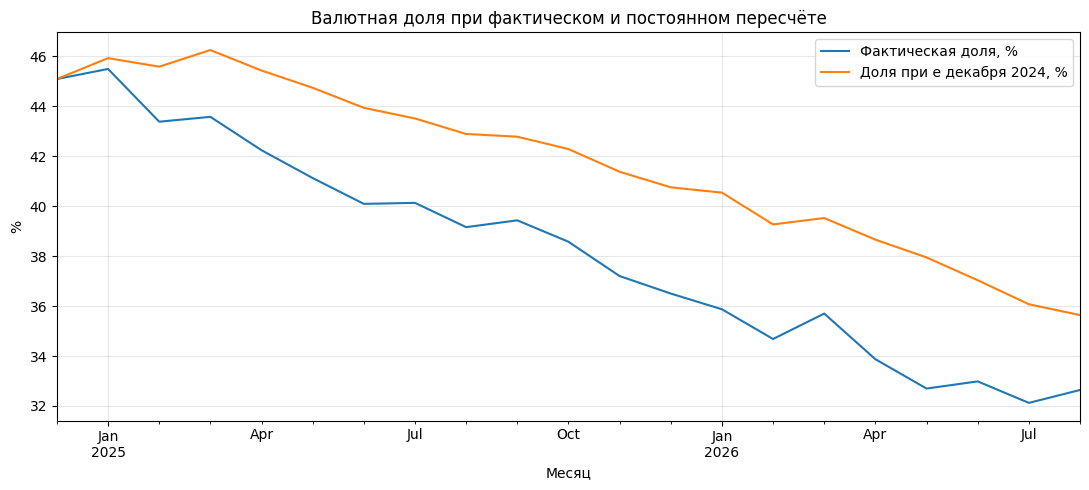

In [43]:
fixed_e = e.loc["2024-12"]

share_fixed_e = currency_share(B, U, fixed_e)

constant_rate_comparison = pd.DataFrame({
    "Фактическая доля, %": 100 * currency_share(B, U, e),
    "Доля при e декабря 2024, %": 100 * share_fixed_e,
}).loc["2024-12":"2026-08"]

display(constant_rate_comparison.tail().round(2))

ax = constant_rate_comparison.plot(figsize=(11, 5))

ax.set_title("Валютная доля при фактическом и постоянном пересчёте")
ax.set_xlabel("Месяц")
ax.set_ylabel("%")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
seasonal_component_predictions = stocks[component_columns].shift(2) * (
    stocks[component_columns].shift(12)
    / stocks[component_columns].shift(14)
)

seasonal_predictions = pd.DataFrame({
    "byn_stock_mln": (
        seasonal_component_predictions["byn_transfer"]
        + seasonal_component_predictions["byn_other"]
    ),
    "fx_stock_usd_mln": (
        seasonal_component_predictions["fx_transfer_usd"]
        + seasonal_component_predictions["fx_other_usd"]
    ),
})

seasonal_metrics = {}

for period_name, (start, end) in periods.items():
    actual = stocks[
        ["byn_stock_mln", "fx_stock_usd_mln"]
    ].loc[start:end]

    predicted = seasonal_predictions.loc[start:end]

    assert predicted.notna().all().all(), "Есть пропуски"

    seasonal_metrics[period_name] = (
        actual - predicted).abs().mean()

seasonal_mae = pd.DataFrame(seasonal_metrics)
seasonal_mae.index = ["BYN, млн BYN", "FX, млн USD-эквивалента"]

display(seasonal_mae.round(3))

,Все 29,Первые 17,Последние 12
"BYN, млн BYN",389.137,460.570,287.941
"FX, млн USD-эквивалента",115.288,103.154,132.479


In [46]:
designs_season = {}

month_features = [f"month_{m}" for m in range(2, 13)]

for component_name in component_columns:
    table = designs_flow[component_name].copy()

    # Строка относится к origin, а цель — следующий месяц.
    target_month = (table.index + 1).month

    for month in range(2, 13):
        table[f"month_{month}"] = (
            target_month == month
        ).astype(int)

    designs_season[component_name] = table

features_season = features + month_features
features_flow_season = features_flow + month_features

display(
    designs_season["byn_transfer"][month_features].head(12)
)

,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
month,,,,,,,,,,,
2020-02,0,1,0,0,0,0,0,0,0,0,0
2020-03,0,0,1,0,0,0,0,0,0,0,0
2020-04,0,0,0,1,0,0,0,0,0,0,0
2020-05,0,0,0,0,1,0,0,0,0,0,0
2020-06,0,0,0,0,0,1,0,0,0,0,0
2020-07,0,0,0,0,0,0,1,0,0,0,0
2020-08,0,0,0,0,0,0,0,1,0,0,0
2020-09,0,0,0,0,0,0,0,0,1,0,0
2020-10,0,0,0,0,0,0,0,0,0,1,0


In [53]:
season_results = []

models = {
    "Ridge + месяцы": features_season,
    "Ridge + flow + месяцы": features_flow_season,
}

for component in component_columns:
    table = designs_season[component]

    for origin in origins_long:
        train = table.loc[
            table.index + 1 <= origin - 1
        ].dropna(subset=features_flow_season + ["y"])

        for name, columns in models.items():
            model = make_pipeline(
                StandardScaler(),
                Ridge(alpha=1),
            )

            model.fit(train[columns], train["y"])

            growth = model.predict(table.loc[[origin], columns])[0]
            prediction = table.loc[origin, "base"] * np.exp(growth / 100)

            season_results.append({
                "month": origin + 1,
                "component": component,
                "model": name,
                "actual": stocks.loc[origin + 1, component],
                "prediction": prediction,
            })

season_results = pd.DataFrame(season_results)
season_results["absolute_error"] = (season_totals["actual"] - season_totals["prediction"]).abs()

display(season_results.head())

,month,component,model,actual,prediction,absolute_error
0,2024-04,byn_transfer,Ridge + месяцы,6545.384,6365.099933,338.712204
1,2024-04,byn_transfer,Ridge + flow + месяцы,6545.384,6772.631930,365.190210
2,2024-05,byn_transfer,Ridge + месяцы,6726.516,6876.290468,74.407148
3,2024-05,byn_transfer,Ridge + flow + месяцы,6726.516,7356.927968,206.970626
4,2024-06,byn_transfer,Ridge + месяцы,7608.707,7738.690412,910.844104


In [50]:
season_results["currency"] = season_results["component"].map(
    currency_groups
)

season_totals = (
    season_results
    .groupby(["month", "currency", "model"])[["actual", "prediction"]]
    .sum()
    .reset_index()
)

ridge_comparison = pd.concat(
    [totals_long, season_totals],
    ignore_index=True,
)

season_comparison = {}

for name, (start, end) in periods.items():
    mask = ridge_comparison["month"].between(
        pd.Period(start, freq="M"),
        pd.Period(end, freq="M"),
    )

    season_comparison[name] = (
        ridge_comparison.loc[mask]
        .groupby(["currency", "model"])["absolute_error"]
        .mean()
    )

season_comparison = pd.DataFrame(season_comparison)

display(season_comparison.round(3))

Все 29  Первые 17  Последние 12
currency model                                                  
BYN      Ridge                  412.050    362.438       482.334
         Ridge + flow           401.456    398.224       406.035
         Ridge + flow + месяцы  415.075    493.067       304.588
         Ridge + месяцы         388.330    379.936       400.222
FX       Ridge                   96.445    101.427        89.386
         Ridge + flow           127.895    140.160       110.519
         Ridge + flow + месяцы  138.979    138.252       140.011
         Ridge + месяцы         109.054    128.897        80.943